# Assignment 1: Data Profiling (EDA) Report (10 marks)
## Data Quality Assessment of Movie Review Data for Viewer Dissatisfaction Analysis

**Course:** Data Engineering  
**Industry Domain:** Entertainment / Streaming Services  
**Prepared:** 31 October 2026

| Name | Matric Number |
|---|---|
| ZHANG YUN | A205865 |
| LIU QINGRONG | A206149 |
| KOU JINGWEN | A207356 |
| ZHANG NIANTIAN | A214108 |

This report diagnoses data quality, documents handling decisions, and validates the resulting tables. It does not train a sentiment model or build a recommendation system. All issue counts and figures below are computed from downloaded source files; no artificial defects are injected.

## 1. Scenario (3 sentences)

A movie streaming platform receives thousands of user comments on its movies and asks which movies viewers are most unhappy with so it can improve its recommendations. Public IMDb review data can be used as a development proxy, but missing ratings, inconsistent representations, extreme review lengths, uncertain title linkage, and privacy or sampling risks may compromise the answer. This assignment asks whether the available review data is sufficiently complete, valid, consistent, and representative for that question, and which defects can be repaired without inventing information.

## 2. Source, acquisition, actual scope, and permitted use

**Source:** [SimpliSolve/RecSysData](https://github.com/SimpliSolve/RecSysData), originally collected from IMDb by its maintainer using Selenium. We download an existing dataset, with no new IMDb scraping. This is third-party collected data, not an IMDb-endorsed release.

**Pinned version:** `64fa993402e02ee77d210ad507ca33452c95f4f8`.  
**Download:** https://codeload.github.com/SimpliSolve/RecSysData/zip/64fa993402e02ee77d210ad507ca33452c95f4f8  
**Source documentation:** https://github.com/SimpliSolve/RecSysData/blob/64fa993402e02ee77d210ad507ca33452c95f4f8/README.md  
**IMDb conditions:** https://www.imdb.com/conditions

Use **all 39 review CSVs** under `user_review_data_daily_search/` (327 reviews), together with all 20 daily metadata CSVs (50 metadata records). We do not select titles based on rating or remove inconvenient observations. The review folder supplies the title; metadata supplies IMDb IDs where an unambiguous title match exists. The Top 250 and MovieLens folders are excluded because they do not supply the corresponding review text for this sample. A folder title is not a globally unique movie identifier.

The source's use disclaimer restricts it to educational/research use and cautions against republishing without compliance with IMDb's terms. This is **not a verified permissive redistribution license**. Consequently this project distributes code, file hashes and aggregate diagnostics, and automatically downloads the archive for local educational analysis; raw and cleaned review text, user handles, and source README copies are excluded from the submission package and Git. Redaction alone does not grant redistribution rights. Any later publication/commercial use requires a separate rights review.

**Scope warning:** This is a small, uneven scraped sample of screen titles, including documentaries and television series (for example, *Cheer*). No verified title-type field is available in these CSVs. We retain and flag this unresolved catalog-scope limitation rather than invent movie/series classifications. It is suitable for this data-quality pilot, not for answering a production movie-only ranking question. The platform scenario remains unchanged.

## 3. Run instructions and reproducibility

Use Python 3.12, open a terminal in the project folder, then run:

```text
python -m venv .venv
# Windows:
.venv\Scripts\activate
# macOS/Linux instead: source .venv/bin/activate
python -m pip install -r requirements.txt
python -m ipykernel install --user --name assignment1 --display-name "Assignment 1"
jupyter notebook Assignment1_Data_Profiling.ipynb
```

Select the **Assignment 1** kernel and **Restart Kernel and Run All Cells**. Keep `data/source_manifest.json` beside the notebook in its `data` folder. The first run needs internet access to download approximately 1.4 MB; later runs verify and reuse the cached archive. No API key, paid service, external drive path or manual CSV download is required. Run from the project root; allow approximately 1 minute and 1 GB RAM. The manifest pins individual file hashes because hosting services may repackage ZIP containers without changing file contents. A mismatch stops execution rather than silently changing results.

For a headless check, after activating the environment, run `python scripts/verify_notebook.py`. It executes with a fresh kernel and checks cell errors, figures, expected source dimensions, and validation results. Local generated data belongs in ignored `data/processed/`; share only the intended submission files.

In [1]:
from pathlib import Path
from io import BytesIO
import hashlib, json, re, zipfile, unicodedata, html, platform, sys
from html.parser import HTMLParser
from datetime import datetime, timezone
import requests
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
assert (ROOT / 'data/source_manifest.json').is_file(), 'Run from the project root with the manifest present.'
for folder in ['data/raw', 'data/processed', 'reports/figures']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
versions = {'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__,
            'matplotlib': matplotlib.__version__, 'requests': requests.__version__}
display(pd.Series(versions, name='Runtime version').to_frame())

,Runtime version
python,3.12.14
pandas,3.1.0
numpy,2.5.4
matplotlib,3.11.2
requests,2.34.2


In [2]:
manifest = json.loads((ROOT / 'data/source_manifest.json').read_text(encoding='utf-8'))
archive_path = ROOT / 'data/raw/recsys.zip'
if not archive_path.exists():
    # Download once, with bounded retries; do not leave an apparently valid partial ZIP.
    for attempt in range(3):
        try:
            response = requests.get(manifest['download_url'], timeout=(15, 120))
            response.raise_for_status()
            payload = response.content
            assert zipfile.is_zipfile(BytesIO(payload)), 'The server did not return a ZIP archive.'
            archive_path.write_bytes(payload)
            break
        except (requests.RequestException, AssertionError):
            if attempt == 2:
                raise
archive_hash = hashlib.sha256(archive_path.read_bytes()).hexdigest()
archive = zipfile.ZipFile(archive_path)
# Read only selected CSV members, never extract arbitrary archive paths.
members = {'/'.join(n.split('/')[1:]): n for n in archive.namelist() if not n.endswith('/')}
for entry in manifest['files']:
    content = archive.read(members[entry['path']])
    assert len(content) == entry['bytes']
    assert hashlib.sha256(content).hexdigest() == entry['sha256'], entry['path']
review_paths = sorted(p for p in members if p.startswith('user_review_data_daily_search/') and p.endswith('.csv'))
metadata_paths = sorted(p for p in members if p.startswith('daily_csvs/') and p.endswith('.csv'))
expected_paths = {e['path'] for e in manifest['files']}
assert set(review_paths + metadata_paths) == expected_paths - {'README.md'}
print(f'Verified {len(manifest["files"])} pinned source files; archive SHA-256: {archive_hash}')
print(f'Review CSVs: {len(review_paths)}; metadata CSVs: {len(metadata_paths)}')

Verified 60 pinned source files; archive SHA-256: cf167afe1af034622c63d8fe3e56e7653109b8fb3e42da6aeb1e8e27aa046feb
Review CSVs: 39; metadata CSVs: 20


### Source schema and unit of observation

One row is one scraped review, **not one viewer**. `Review_number` is a local per-title sequence, not a global review ID. `User_rating` is a reviewer's 1–10 rating, not the movie's aggregate `movie_rating`. `Created_at` is documented as the **extraction date**; we must not use it as the review publication date. The documented review fields are `Review_number`, `User_rating`, `Review_title`, `User_id`, `User_id_link`, `Created_at`, `Review_Text`, and `Spoiler`.

Read every original cell as a string and preserve missing sentinels initially. This makes the distinction between physical blanks and logical missingness visible, rather than allowing CSV inference to hide it. Added provenance fields are `source_file` and `movie_title_raw` (the source folder name). Full raw comments and user identifiers are deliberately not displayed in notebook outputs.

In [3]:
def read_csv_member(path):
    return pd.read_csv(BytesIO(archive.read(members[path])), dtype=str, keep_default_na=False)

frames = []
expected_columns = ['Review_number', 'User_rating', 'Review_title', 'User_id', 'User_id_link',
                    'Created_at', 'Review_Text', 'Spoiler']
for path in review_paths:
    frame = read_csv_member(path)
    assert frame.columns.tolist() == expected_columns, f'Unexpected schema: {path}'
    frames.append(frame.assign(movie_title_raw=path.split('/')[1], source_file=path))
raw = pd.concat(frames, ignore_index=True)
metadata = pd.concat([read_csv_member(p) for p in metadata_paths], ignore_index=True)
assert raw.shape == (327, 10) and raw['movie_title_raw'].nunique() == 39
assert len(metadata) == 50
print(f'Initial reviews: {len(raw)}; title folders: {raw.movie_title_raw.nunique()}; metadata rows: {len(metadata)}')
profile = pd.DataFrame({'dtype': raw.dtypes.astype(str), 'unique_values': raw.nunique(),
                        'physical_blank_cells': raw.apply(lambda s: s.str.strip().eq('').sum()),
                        'literal_na_tokens': raw.apply(lambda s: s.str.strip().str.casefold().isin(['n/a','na','none','null','nan']).sum())})
display(profile)
display(raw['User_rating'].value_counts(dropna=False).rename_axis('Raw rating token').to_frame('Reviews'))
display(raw['Review_Text'].str.len().describe(percentiles=[.25,.5,.75,.95,.99]).rename('Raw text characters').to_frame())
print('Exact source payload duplicate excess:', int(raw.duplicated(expected_columns + ['movie_title_raw']).sum()))
print('Repeated local review numbers across different titles are expected:', int(raw.Review_number.duplicated().sum()))

Initial reviews: 327; title folders: 39; metadata rows: 50


,dtype,unique_values,physical_blank_cells,literal_na_tokens
Review_number,str,25,0,0
User_rating,str,11,0,8
Review_title,str,320,0,0
User_id,str,316,0,8
User_id_link,str,1,0,327
Created_at,str,1,0,0
Review_Text,str,327,0,0
Spoiler,str,2,0,0
movie_title_raw,str,39,0,0
source_file,str,39,0,0


,Reviews
Raw rating token,
10,148
9,48
8,28
7,21
1,20
3,17
6,11
4,10
5,10


,Raw text characters
count,327.000000
mean,649.262997
std,809.564841
min,53.000000
25%,228.500000
50%,405.000000
75%,766.500000
95%,2092.500000
99%,4562.960000
max,7313.000000


Exact source payload duplicate excess: 0
Repeated local review numbers across different titles are expected: 302


## 4. Missing values: diagnosis and decisions

Treat case-insensitive `n/a`, `na`, `none`, `null`, `nan` and whitespace-only cells as missing. Do not count a missing literal token as a real username or a valid rating. Report both counts and percentages for every imported review field.

* **Ratings:** retain reviews with missing ratings, flag them, and omit them from the rating-ready view. Mean/median or text-based imputation would invent the viewer's opinion and distort dissatisfaction rates.
* **User handles:** not required for the business question; report completeness, then remove from the analytical export. Missing handles also prevent reliable person-level deduplication.
* **Profile links:** if entirely absent, drop the useless column; even complete links would be unnecessary personal identifiers here.
* **Required review text/title:** if absent, quarantine the row separately instead of inventing a comment or movie title. Report a zero count if none occur.
* **IMDb ID:** only fill through an unambiguous exact normalized title match to source metadata. Leave unresolved links missing and out of the ID-based rating view; do not guess IDs with fuzzy title matching.

In [4]:
NA_TOKENS = {'', 'n/a', 'na', 'none', 'null', 'nan'}
def missing_mask(series):
    return series.isna() | series.astype('string').str.strip().str.casefold().isin(NA_TOKENS)

def normalized_string(series):
    return series.astype('string').mask(missing_mask(series)).str.normalize('NFC').str.strip()

missing_initial = pd.DataFrame({'missing_count': raw.apply(lambda s: int(missing_mask(s).sum()))})
missing_initial['missing_percent'] = (missing_initial.missing_count / len(raw) * 100).round(2)
display(missing_initial)
stage = raw.apply(normalized_string)
stage['movie_title'] = stage.movie_title_raw.str.replace(r'\s+', ' ', regex=True)
meta = metadata[['movie_name', 'movie_link']].apply(normalized_string)
meta['title_key'] = meta.movie_name.str.replace(r'\s+', ' ', regex=True)
meta['movie_id'] = meta.movie_link.str.extract(r'/title/(tt\d+)/', expand=False)
meta_distinct = meta[['title_key','movie_id']].drop_duplicates()
ambiguous_titles = meta_distinct.groupby('title_key', dropna=False).movie_id.nunique().loc[lambda x:x > 1].index
lookup = (meta_distinct.loc[~meta_distinct.title_key.isin(ambiguous_titles)]
          .dropna(subset=['movie_id']).drop_duplicates('title_key').set_index('title_key').movie_id)
stage['movie_id'] = stage.movie_title.map(lookup).astype('string')
stage['movie_id_unresolved'] = stage.movie_id.isna()
display(pd.DataFrame({'quantity': ['Ambiguous metadata title keys', 'Reviews without a resolved IMDb ID',
                                  'Source titles without a resolved IMDb ID'],
                      'count': [len(ambiguous_titles), int(stage.movie_id.isna().sum()),
                                stage.loc[stage.movie_id.isna(),'movie_title'].nunique()]}))

,missing_count,missing_percent
Review_number,0,0.00
User_rating,8,2.45
Review_title,0,0.00
User_id,8,2.45
User_id_link,327,100.00
Created_at,0,0.00
Review_Text,0,0.00
Spoiler,0,0.00
movie_title_raw,0,0.00
source_file,0,0.00


,quantity,count
0,Ambiguous metadata title keys,0
1,Reviews without a resolved IMDb ID,143
2,Source titles without a resolved IMDb ID,16


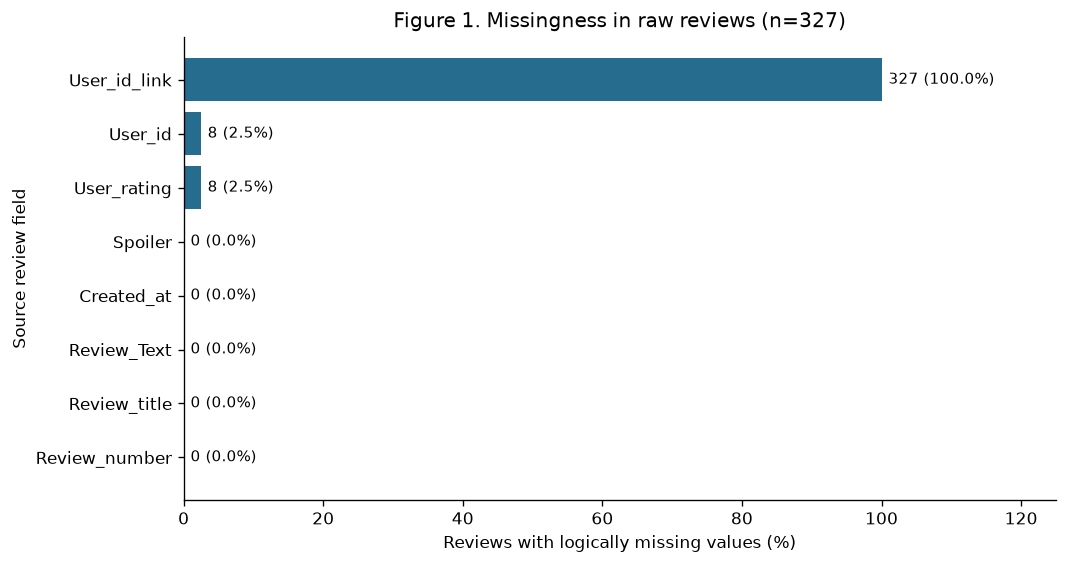

**Diagnosis:** 8 ratings are missing; 327 profile links are missing. Missing opinions are flagged, not imputed; profile links will be removed.

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.8))
plot_missing = missing_initial.loc[expected_columns, 'missing_percent'].sort_values()
bars = ax.barh(plot_missing.index, plot_missing.values, color='#266C8E')
for bar, field in zip(bars, plot_missing.index):
    count = int(missing_initial.loc[field, 'missing_count'])
    ax.text(bar.get_width()+1, bar.get_y()+bar.get_height()/2, f'{count} ({bar.get_width():.1f}%)', va='center', fontsize=9)
ax.set(xlim=(0,125), xlabel='Reviews with logically missing values (%)', ylabel='Source review field',
       title=f'Figure 1. Missingness in raw reviews (n={len(raw)})')
fig.tight_layout(); fig.savefig(ROOT/'reports/figures/01_missing_values.png', bbox_inches='tight'); plt.show()
display(Markdown(f'**Diagnosis:** {int(missing_initial.loc["User_rating","missing_count"])} ratings are missing; '
                 f'{int(missing_initial.loc["User_id_link","missing_count"])} profile links are missing. '
                 'Missing opinions are flagged, not imputed; profile links will be removed.'))

## 5. Other quality issues: types, formats, validity and duplicates

**Types and valid domains:** convert ratings to nullable integers only if numeric, integral and within 1–10; convert local review numbers to positive nullable integers; parse the explicit day/month/year extraction date; map the two documented spoiler tokens to nullable Boolean. Preserve missing and invalid flags before coercion. Unknown spoiler tokens and bad extraction dates remain missing, with flags, rather than guessed values. Bounds are validity rules, not statistical outlier rules: a score of 1 is a valid negative opinion.

**Text consistency:** standardize NFC Unicode, decode HTML entities, replace HTML line-break/block tags with whitespace, and collapse whitespace. Preserve casing, punctuation, negation and non-English characters because they carry meaning. Count actual changes; an available cleaning function is not evidence of an observed defect. HTML parsing may have edge cases, so no claim of perfect semantic preservation is made.

**Duplicates:** first check exact source-payload repeats; then flag normalized repeated content within a title and duplicates of the title/local-number key. Review numbers repeated across movies are not duplicates. Remove only conservative repeat records agreeing on normalized title, known user handle, text, rating, extraction date and spoiler state. Missing handles, conflicting ratings, or text reused across different titles require review and are not automatically collapsed. The absence of actual duplicates must be reported honestly.

In [6]:
rating_numeric = pd.to_numeric(stage.User_rating, errors='coerce')
valid_rating = (rating_numeric.between(1,10) & rating_numeric.mod(1).eq(0)).fillna(False)
stage['rating_missing_source'] = stage.User_rating.isna()
stage['rating_invalid_source'] = stage.User_rating.notna() & ~valid_rating
stage['rating'] = rating_numeric.where(valid_rating).astype('Int64')
seq = pd.to_numeric(stage.Review_number, errors='coerce')
valid_seq = (seq.ge(1) & seq.mod(1).eq(0)).fillna(False)
stage['review_number_invalid'] = stage.Review_number.notna() & ~valid_seq
stage['review_number'] = seq.where(valid_seq).astype('Int64')
stage['extraction_date'] = pd.to_datetime(stage.Created_at, format='%d/%m/%Y', errors='coerce')
stage['date_invalid_source'] = stage.Created_at.notna() & stage.extraction_date.isna()
spoiler_map = {'true': True, 'false': False}
stage['spoiler'] = stage.Spoiler.str.casefold().map(spoiler_map).astype('boolean')
stage['spoiler_invalid_source'] = stage.Spoiler.notna() & stage.spoiler.isna()

class PlainText(HTMLParser):
    def __init__(self):
        super().__init__(convert_charrefs=True)
        self.parts = []
    def handle_data(self, data):
        self.parts.append(data)
    def handle_starttag(self, tag, attrs):
        if tag.lower() in {'br','p','div','li'}:
            self.parts.append(' ')
    def handle_endtag(self, tag):
        if tag.lower() in {'p','div','li'}:
            self.parts.append(' ')

def clean_text(value):
    if pd.isna(value):
        return pd.NA
    # Parse only strings with recognizable tags to avoid treating ordinary comparisons as HTML.
    if re.search(r'</?[a-zA-Z][^>]*>', value):
        parser = PlainText(); parser.feed(value); parser.close()
        value = ''.join(parser.parts)
    return re.sub(r'\s+', ' ', unicodedata.normalize('NFC', html.unescape(value))).strip() or pd.NA

stage['review_text'] = stage.Review_Text.map(clean_text).astype('string')
stage['review_title'] = stage.Review_title.map(clean_text).astype('string')
text_changed = stage.review_text.fillna('').ne(raw.Review_Text.fillna(''))
title_changed = stage.review_title.fillna('').ne(raw.Review_title.fillna(''))
stage['text_chars'] = stage.review_text.str.len().astype('Int64')
stage['local_key_duplicate'] = stage.duplicated(['movie_title','review_number'], keep=False)
stage['normalized_content_repeat'] = stage.duplicated(['movie_title','review_text'], keep=False)
duplicate_key = ['movie_title','User_id','review_text','rating','extraction_date','spoiler']
stage['duplicate_excess'] = stage.User_id.notna() & stage.duplicated(duplicate_key, keep='first')
issue_counts = {
    'Invalid nonmissing ratings': int(stage.rating_invalid_source.sum()),
    'Invalid local review numbers': int(stage.review_number_invalid.sum()),
    'Unparseable nonmissing extraction dates': int(stage.date_invalid_source.sum()),
    'Unknown nonmissing spoiler tokens': int(stage.spoiler_invalid_source.sum()),
    'Changed review texts': int(text_changed.sum()),
    'Bodies containing recognizable HTML tags': int(raw.Review_Text.str.contains(r'</?[a-zA-Z][^>]*>',regex=True).sum()),
    'Bodies with repeated or boundary whitespace': int(raw.Review_Text.map(lambda x: re.sub(r'\s+', ' ', x).strip()!=x).sum()),
    'Bodies changed by NFC normalization': int(raw.Review_Text.map(lambda x: unicodedata.normalize('NFC',x)!=x).sum()),
    'Changed review titles': int(title_changed.sum()),
    'Rows in duplicate local keys': int(stage.local_key_duplicate.sum()),
    'Rows in normalized title/text repeats': int(stage.normalized_content_repeat.sum()),
    'Conservative duplicate excess to remove': int(stage.duplicate_excess.sum())}
display(pd.Series(issue_counts, name='Observed rows').to_frame())
display(stage[['rating','review_number','extraction_date','spoiler','review_text']].dtypes.astype(str).to_frame('Converted dtype'))

,Observed rows
Invalid nonmissing ratings,0
Invalid local review numbers,0
Unparseable nonmissing extraction dates,0
Unknown nonmissing spoiler tokens,0
Changed review texts,39
Bodies containing recognizable HTML tags,0
Bodies with repeated or boundary whitespace,39
Bodies changed by NFC normalization,0
Changed review titles,0
Rows in duplicate local keys,0


,Converted dtype
rating,Int64
review_number,Int64
extraction_date,datetime64[us]
spoiler,boolean
review_text,string


## 6. Outliers: detection, interpretation and retention

Use review length in characters after format normalization, before privacy masking. Compute Q1, Q3 and the 1.5 × IQR fences on all nonempty normalized texts; flag values outside either fence. This is a **screening heuristic**, not a definition of erroneous text: natural review lengths have a long right tail. The table reports the five largest lengths and their flags without reproducing comments or usernames.

Retain nonempty long and short reviews without capping or truncating; short complaints and detailed criticism may both be important. We cannot verify authenticity just from length. Ratings are checked against the source's 1–10 domain, with no IQR-based deletion of low scores. Downstream ingestion may enforce a documented operational text-size limit, but none is invented here. A retention sensitivity table measures how deleting flagged lengths would change rating coverage and the observed low-rating share; it is a diagnostic, not a movie ranking.

,Length diagnostic
Q1 (characters),228.50
Q3 (characters),766.50
IQR (characters),538.00
Lower fence,-578.50
Upper fence,1573.50
Flagged reviews,22.00
Flagged percent,6.73


,text_chars,length_outlier
0,7313,True
1,5985,True
2,4941,True
3,4915,True
4,3561,True


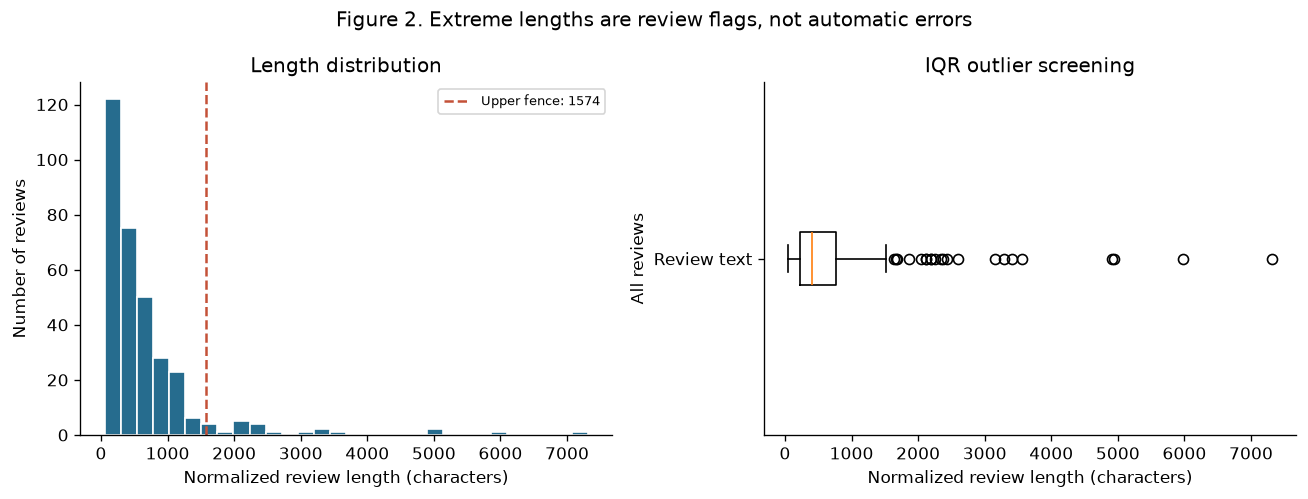

,policy,reviews,rated_reviews,low_rating_share_percent
0,Keep all valid lengths (chosen),327,319,16.61
1,Hypothetical exclusion of length flags,305,299,16.39


In [7]:
q1, q3 = stage.text_chars.dropna().astype(float).quantile([.25,.75])
iqr = q3-q1
lower_fence, upper_fence = q1-1.5*iqr, q3+1.5*iqr
stage['length_outlier'] = ((stage.text_chars < lower_fence) | (stage.text_chars > upper_fence)).fillna(False)
display(pd.Series({'Q1 (characters)': q1, 'Q3 (characters)': q3, 'IQR (characters)': iqr,
                   'Lower fence': lower_fence, 'Upper fence': upper_fence,
                   'Flagged reviews': int(stage.length_outlier.sum()),
                   'Flagged percent': round(stage.length_outlier.mean()*100,2)}, name='Length diagnostic').to_frame())
display(stage[['text_chars','length_outlier']].nlargest(5,'text_chars').reset_index(drop=True))
fig, axes = plt.subplots(1,2,figsize=(11,4.2))
axes[0].hist(stage.text_chars.dropna().astype(float), bins=30, color='#266C8E', edgecolor='white')
axes[0].axvline(upper_fence,color='#C45138',linestyle='--',label=f'Upper fence: {upper_fence:.0f}')
axes[0].set(xlabel='Normalized review length (characters)',ylabel='Number of reviews',title='Length distribution'); axes[0].legend(fontsize=8)
axes[1].boxplot(stage.text_chars.dropna().astype(float),orientation='horizontal',whis=1.5)
axes[1].set(xlabel='Normalized review length (characters)',ylabel='All reviews',yticks=[1],yticklabels=['Review text'],title='IQR outlier screening')
fig.suptitle('Figure 2. Extreme lengths are review flags, not automatic errors')
fig.tight_layout(); fig.savefig(ROOT/'reports/figures/02_length_outliers.png',bbox_inches='tight'); plt.show()

def rating_summary(frame, label):
    rated = frame.rating.dropna()
    return {'policy':label, 'reviews':len(frame), 'rated_reviews':len(rated),
            'low_rating_share_percent': round(rated.le(4).mean()*100,2) if len(rated) else None}
display(pd.DataFrame([rating_summary(stage,'Keep all valid lengths (chosen)'),
                      rating_summary(stage.loc[~stage.length_outlier],'Hypothetical exclusion of length flags')]))

## 7. PII and bias: measured risks and handling

**PII minimization:** user handles/profile links can enable re-identification even though they are public. Use handles transiently for conservative repeat detection and remove them from exported analytical data. Also omit the original text and source-file path from the cleaned export; a path alone can still aid linkage and is retained only in the private audit table. The cleaned text may contain first-person disclosures, names, email addresses, health or other sensitive details. Regex-screen review bodies and review titles for explicit emails and HTTP/WWW links, replace detected spans with typed placeholders, and record how many rows are affected. Zero matches do not prove the absence of PII. This screen does not reliably detect names, phone numbers, indirect identifiers, context, or minors; it is **not anonymization**. Local access restriction and no text redistribution remain necessary. The five students' names and matric numbers appear only because the assignment explicitly requires them.

**Observed coverage:** review counts vary by title, ratings may be missing unevenly, and IMDb ID mapping is incomplete. Diagnose group coverage with counts and per-title missing-rating rates. A source page may contain at most 25 reviews here; this resembles a truncated page sample, but we cannot prove the ordering or completeness. The source date field records extraction, so time trends in viewer opinion cannot be inferred.

**Selection and generalization:** source documentation includes minimum-vote/runtime filters and multiple title types. Volunteer IMDb reviewers, early-2020 source date blocks, documentaries/series, a small catalog and unusually high scores may not represent current streaming viewers. Demographic and language coverage are unknown; do not infer protected characteristics from names or comments. Avoid popularity rankings by raw complaint counts. Future analysis needs verified movie-only IDs, broader sampling, publication timestamps, exposure denominators, and explicit per-title sample size/uncertainty. Report missing-rating sensitivity; do not balance this dataset by inventing or duplicating negative reviews. No weighting can repair unknown inclusion probabilities.

,Reviews matching pattern in text or title
email,0
url,0


,reviews,missing_ratings,unresolved_id,missing_rating_percent
movie_title,,,,
Crip Camp,25,2,False,8.0
Cheer,25,0,False,0.0
James May Our Man in,25,0,True,0.0
Uppity The Willy T. Ribbs Story,25,0,True,0.0
Wild Karnataka,24,1,False,4.17
The ParaPod A Very British Ghost Hunt,23,2,True,8.7
Better,21,0,False,0.0
"Cryptopia Bitcoin, Blockchains and the Future of the Internet",20,0,True,0.0
The Invisible Class,19,0,False,0.0


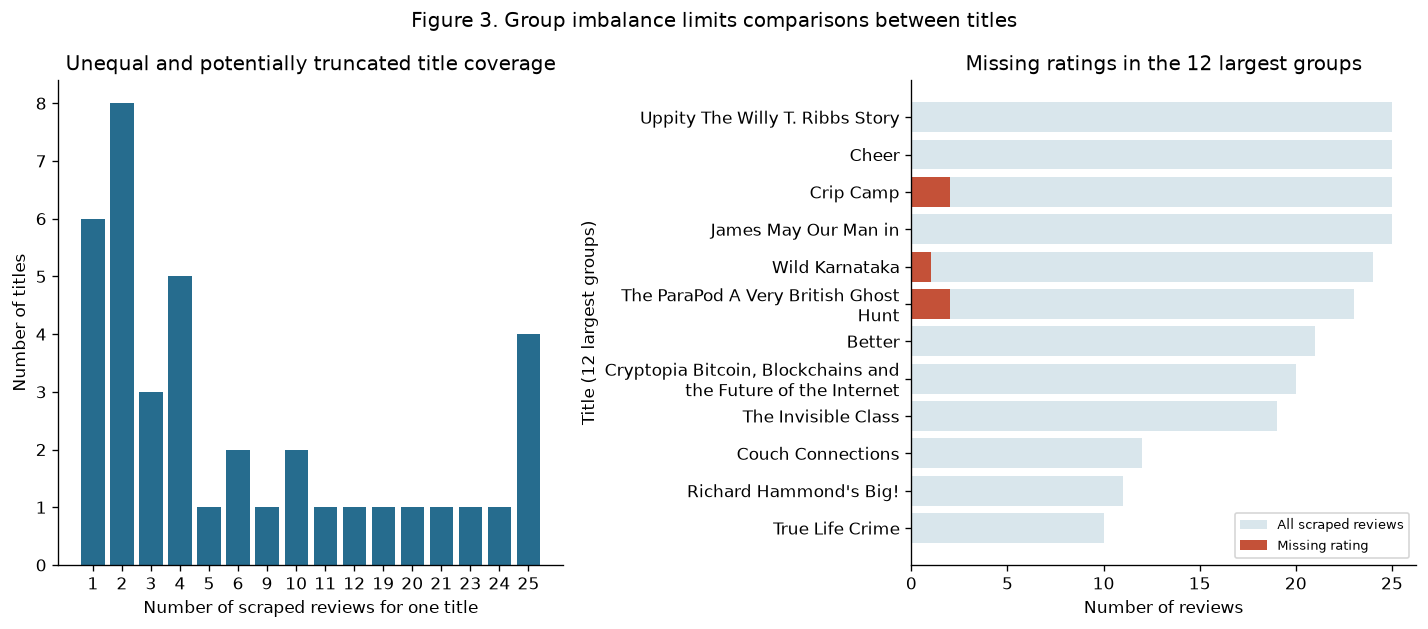

,Missing-rating sensitivity (sample only; low = 1–4)
Rated reviews,319.00
Missing or invalid ratings,8.00
Observed low-rating share among rated reviews (%),16.61
Lower bound if all unrated reviews are not low (%),16.21
Upper bound if all unrated reviews are low (%),18.65


In [8]:
PII_PATTERNS = {
    'email': re.compile(r'(?i)\b[A-Z0-9._%+-]+@[A-Z0-9.-]+\.[A-Z]{2,}\b'),
    'url': re.compile(r'(?i)(?:https?://|www\.)[^\s<>]+')}
pii_counts = {}
stage['pii_pattern_flag'] = False
for label, pattern in PII_PATTERNS.items():
    found = (stage.review_text.fillna('').str.contains(pattern,regex=True)
             | stage.review_title.fillna('').str.contains(pattern,regex=True))
    pii_counts[label] = int(found.sum())
    stage['pii_pattern_flag'] |= found

def redact_patterns(value):
    if pd.isna(value): return pd.NA
    for label, pattern in PII_PATTERNS.items():
        value = pattern.sub(f'[{label.upper()}_REDACTED]', value)
    return value

display(pd.Series(pii_counts,name='Reviews matching pattern in text or title').to_frame())
coverage = stage.groupby('movie_title').agg(reviews=('movie_title','size'),
           missing_ratings=('rating',lambda s:int(s.isna().sum())),
           unresolved_id=('movie_id',lambda s:bool(s.isna().all())))
coverage['missing_rating_percent'] = (coverage.missing_ratings/coverage.reviews*100).round(2)
display(coverage.sort_values(['reviews','missing_ratings'],ascending=False).head(12))
fig, axes = plt.subplots(1,2,figsize=(12,5.3))
counts = coverage.reviews.value_counts().sort_index()
axes[0].bar(counts.index.astype(str),counts.values,color='#266C8E')
axes[0].set(xlabel='Number of scraped reviews for one title',ylabel='Number of titles',title='Unequal and potentially truncated title coverage')
top = coverage.sort_values('reviews',ascending=False).head(12).sort_values('reviews')
import textwrap
labels = [textwrap.fill(t, width=34) for t in top.index]
axes[1].barh(labels,top.reviews,color='#D9E6EC',label='All scraped reviews')
axes[1].barh(labels,top.missing_ratings,color='#C45138',label='Missing rating')
axes[1].set(xlabel='Number of reviews',ylabel='Title (12 largest groups)',title='Missing ratings in the 12 largest groups')
axes[1].legend(fontsize=8)
fig.suptitle('Figure 3. Group imbalance limits comparisons between titles')
fig.tight_layout(); fig.savefig(ROOT/'reports/figures/03_title_coverage.png',bbox_inches='tight'); plt.show()

known = int(stage.rating.notna().sum()); low = int(stage.rating.le(4).sum()); unknown = int(stage.rating.isna().sum())
display(pd.Series({'Rated reviews':known, 'Missing or invalid ratings':unknown,
    'Observed low-rating share among rated reviews (%)':round(100*low/known,2),
    'Lower bound if all unrated reviews are not low (%)':round(100*low/len(stage),2),
    'Upper bound if all unrated reviews are low (%)':round(100*(low+unknown)/len(stage),2)},
    name='Missing-rating sensitivity (sample only; low = 1–4)').to_frame())

## 8. Build cleaned views, preserve an audit trail, and validate

The **cleaned review table** retains all usable text/title rows, including missing ratings and unresolved IMDb links. Quarantine only missing required text/title, then remove conservative duplicates. The **rating-ready view** requires both a valid score and a resolved IMDb ID; it is a technical staging view, not certified movie-only or representative data. Known TV contamination remains unresolved and blocks use for movie rankings. No valid extreme opinion or long review is removed.

Write a private, row-level audit table containing source locations and flags but no user handles or original text. Keep the audit table and both text-bearing outputs out of Git. Write only text-free summary tables, aggregate metrics and charts to `reports/` for the submission. Validate row conservation, nullable typed values, required completeness, masking, duplicate policy and consistency between the two views. Run the transformation twice to check text-cleaning idempotence. A validation pass means the implemented contracts passed, not that semantic accuracy, representativeness, anonymization or licensing have been established.

In [9]:
stage['required_missing'] = stage.movie_title.isna() | stage.review_text.isna()
quarantine_mask = stage.required_missing
dedup_mask = ~quarantine_mask & stage.duplicate_excess
keep_mask = ~quarantine_mask & ~dedup_mask
clean = stage.loc[keep_mask, ['movie_title','movie_id','review_number','rating','review_title','review_text',
             'extraction_date','spoiler','rating_missing_source','rating_invalid_source','movie_id_unresolved',
             'length_outlier','pii_pattern_flag','text_chars']].copy()
for field in ['review_text','review_title']:
    clean[field] = clean[field].map(redact_patterns).astype('string')
clean['rating_unavailable'] = clean.rating.isna()
clean['catalog_type_unverified'] = True
rating_ready = clean.loc[clean.rating.notna() & clean.movie_id.notna()].copy()
audit = stage[['source_file','Review_number','rating_missing_source','rating_invalid_source',
              'review_number_invalid','date_invalid_source','spoiler_invalid_source','movie_id_unresolved',
              'local_key_duplicate','normalized_content_repeat','duplicate_excess','length_outlier',
              'pii_pattern_flag','required_missing']].copy()
audit['action'] = np.select([quarantine_mask,dedup_mask],['quarantine_required_missing','drop_conservative_duplicate'],default='retain')
audit.to_csv(ROOT/'data/processed/private_row_audit.csv',index=False)
clean.to_csv(ROOT/'data/processed/cleaned_reviews_LOCAL_ONLY.csv',index=False)
rating_ready.to_csv(ROOT/'data/processed/rating_ready_LOCAL_ONLY.csv',index=False)
# Quarantine locations/flags only; raw payloads stay in the private source archive.
audit.loc[quarantine_mask].to_csv(ROOT/'data/processed/quarantine_audit.csv',index=False)

before_after = pd.DataFrame({
    'metric':['Review rows','Missing ratings (retained honestly)','Missing required title/text',
              'Unresolved IMDb IDs','Nonmissing invalid ratings','Known user identifiers exposed in analytical export',
              'Text/title rows matching screened email/URL patterns','Length flags (retained)'],
    'before':[len(raw),int(stage.rating.isna().sum()),int(quarantine_mask.sum()),int(stage.movie_id.isna().sum()),
              int(stage.rating_invalid_source.sum()),int(stage.User_id.notna().sum()),
              int(stage.pii_pattern_flag.sum()),int(stage.length_outlier.sum())],
    'after':[len(clean),int(clean.rating.isna().sum()),int((clean.movie_title.isna()|clean.review_text.isna()).sum()),
             int(clean.movie_id.isna().sum()),int((clean.rating.notna() & ~clean.rating.between(1,10)).sum()),0,
             0,
             int(clean.length_outlier.sum())]})
# Count rows, not pattern occurrences (one review can match more than one pattern).
post_pii = pd.Series(False,index=clean.index)
for pattern in PII_PATTERNS.values():
    post_pii |= (clean.review_text.fillna('').str.contains(pattern,regex=True)
                 | clean.review_title.fillna('').str.contains(pattern,regex=True))
before_after.loc[6,'after'] = int(post_pii.sum())
display(before_after)
before_after.to_csv(ROOT/'reports/before_after.csv',index=False)
coverage.to_csv(ROOT/'reports/title_coverage.csv')
missing_initial.to_csv(ROOT/'reports/initial_missingness.csv')

checks = {
    'row_conservation': len(raw) == len(clean)+int(quarantine_mask.sum())+int(dedup_mask.sum()),
    'required_text_and_title_complete': not (clean.review_text.isna()|clean.movie_title.isna()).any(),
    'rating_domain_and_nullable_integer': str(clean.rating.dtype)=='Int64' and clean.rating.dropna().between(1,10).all(),
    'review_number_positive_integer': str(clean.review_number.dtype)=='Int64' and clean.review_number.dropna().ge(1).all(),
    'date_is_datetime': pd.api.types.is_datetime64_any_dtype(clean.extraction_date),
    'spoiler_is_nullable_boolean': str(clean.spoiler.dtype)=='boolean',
    'resolved_ids_match_imdb_pattern': clean.movie_id.dropna().str.fullmatch(r'tt\d+').all(),
    'missing_ratings_not_imputed': clean.loc[clean.rating_missing_source,'rating'].isna().all(),
    'missing_flags_match_values': clean.rating_unavailable.equals(clean.rating.isna()),
    'identifiers_removed': not {'User_id','User_id_link','source_file','Review_Text'}.intersection(clean.columns),
    'screened_patterns_absent': not post_pii.any(),
    'text_cleaner_idempotent': stage.review_text.equals(stage.review_text.map(clean_text).astype('string')),
    'chosen_duplicate_policy_applied': not stage.loc[keep_mask,'duplicate_excess'].any(),
    'length_flags_retained': int(clean.length_outlier.sum())==int(stage.loc[keep_mask,'length_outlier'].sum()),
    'rating_view_complete_and_subset': rating_ready.rating.notna().all() and rating_ready.movie_id.notna().all()
                                      and rating_ready.index.isin(clean.index).all(),
    'unverified_catalog_scope_flagged': clean.catalog_type_unverified.all()}
checks = {k:bool(v) for k,v in checks.items()}
display(pd.Series(checks,name='Passed').to_frame())
assert all(checks.values()), 'A quality contract failed; inspect the checks above.'
summary = {'source_commit':manifest['commit'],'archive_sha256':archive_hash,'raw_reviews':len(raw),
    'source_titles':int(raw.movie_title_raw.nunique()),'clean_reviews':len(clean),
    'quarantined_rows':int(quarantine_mask.sum()),'duplicates_removed':int(dedup_mask.sum()),
    'missing_source_ratings':int(stage.rating_missing_source.sum()),'unresolved_id_reviews':int(clean.movie_id.isna().sum()),
    'rating_ready_reviews':len(rating_ready),'length_outliers_retained':int(clean.length_outlier.sum()),
    'text_format_changes':int(text_changed.sum()),'pii_pattern_rows':int(stage.pii_pattern_flag.sum()),
    'issue_counts':issue_counts,'checks':checks,'versions':versions}
(ROOT/'reports/quality_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
print('All quality contracts passed. Outputs are local; text-bearing data must not be published.')

,metric,before,after
0,Review rows,327,327
1,Missing ratings (retained honestly),8,8
2,Missing required title/text,0,0
3,Unresolved IMDb IDs,143,143
4,Nonmissing invalid ratings,0,0
5,Known user identifiers exposed in analytical e...,319,0
6,Text/title rows matching screened email/URL pa...,0,0
7,Length flags (retained),22,22


,Passed
row_conservation,True
required_text_and_title_complete,True
rating_domain_and_nullable_integer,True
review_number_positive_integer,True
date_is_datetime,True
spoiler_is_nullable_boolean,True
resolved_ids_match_imdb_pattern,True
missing_ratings_not_imputed,True
missing_flags_match_values,True
identifiers_removed,True


All quality contracts passed. Outputs are local; text-bearing data must not be published.


## 9. Conclusion

The executed summary below distinguishes repairs from unresolved limitations. We have standardized actual strings and types, explicitly represented missing ratings, linked only unambiguous source titles, screened limited direct-identifier patterns, and retained valid extremes. Zero counts for invalid ratings or duplicates are valid findings; this report does not invent problems to satisfy a checklist.

In [10]:
display(Markdown(
    f'**Measured result:** {len(raw)} raw reviews across {raw.movie_title_raw.nunique()} source titles '
    f'became {len(clean)} cleaned reviews; {int(quarantine_mask.sum())} rows were quarantined and '
    f'{int(dedup_mask.sum())} conservative duplicates were removed. '
    f'{int(stage.rating_missing_source.sum())} source ratings were missing and were not imputed. '
    f'{int(text_changed.sum())} review bodies changed during format normalization, '
    f'{int(clean.length_outlier.sum())} length outliers were retained, and '
    f'{int(stage.pii_pattern_flag.sum())} reviews matched the limited PII screen. '
    f'{len(rating_ready)} reviews meet the rating-and-ID staging contract; '
    f'{int(clean.movie_id.isna().sum())} cleaned reviews still lack a resolved IMDb ID. '
    f'All {len(checks)} validation checks passed.'))

**Measured result:** 327 raw reviews across 39 source titles became 327 cleaned reviews; 0 rows were quarantined and 0 conservative duplicates were removed. 8 source ratings were missing and were not imputed. 39 review bodies changed during format normalization, 22 length outliers were retained, and 0 reviews matched the limited PII screen. 179 reviews meet the rating-and-ID staging contract; 143 cleaned reviews still lack a resolved IMDb ID. All 16 validation checks passed.

**Fitness decision:** The cleaned data is fit for a reproducible educational profiling pilot and for developing ingestion quality checks. It is **not yet fit to identify the movies streaming viewers are most unhappy with**: the sample has only 327 reviews, unresolved movie links, unknown catalog types, a single extraction date, missing scores, unverified review authenticity, possible residual PII and strong selection/coverage bias. The rating-ready view does not remove those conceptual limitations. No production ranking, causal recommendation claim or general dissatisfaction estimate is justified.

**Next data-engineering steps:** obtain authorized and more representative platform feedback with stable review/movie IDs, verified movie types and publication dates; resolve catalog linkage against a trusted catalog; review uncertain duplicate/conflicting records and sensitive text under controlled access; monitor completeness, validity, volume and per-title coverage on each ingestion. Then define a minimum per-movie sample size and uncertainty reporting before any later dissatisfaction analysis. Aggregation by user is not supported after identifier minimization and must not be fabricated.

### References and submission status

1. SimpliSolve. *RecSysData*, pinned repository and original README linked in Section 2; accessed 31 October 2026. Source-specific usage restrictions apply.
2. IMDb. *Conditions of Use*, linked in Section 2. Public availability does not imply permission to redistribute.
3. Course handout, *Assignment 1: Data Profiling (EDA) Report (10 marks)*, supplied by the student. Requirements are covered in Sections 1–9, with labeled diagnostic Figures 1–3 and run instructions in Section 3.

